# Scipy notebook 20/10/2026
### Brais Otero Lema

Exercise 1. Chain normal modes.

K symmetric: True
Average absolute deviation from analytical result: 0.03622456844919549


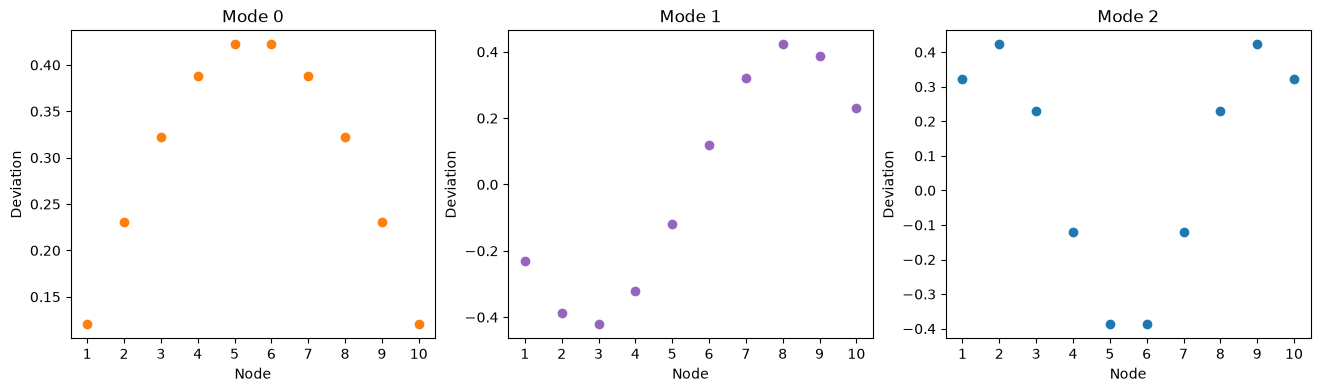

In [1]:
import numpy as np
import scipy as sp
from matplotlib.pyplot import subplots, MultipleLocator

N = 10
k, m = 1., 1.

K = k * (2 * np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1))
print(f"K symmetric: {sp.linalg.issymmetric(K)}")

w, v = sp.linalg.eigh(K/m)

freqs = np.sqrt(w)
analytical = [2 * np.sqrt(k/m) * np.sin(j*np.pi/(2*N + 1)) for j in range(1, N+1)]
print(f"Average absolute deviation from analytical result: {np.mean(np.abs(freqs - analytical))}")

fig, axs = subplots(1, 3, figsize=(16, 4))

colors = ("tab:orange", "tab:purple", "tab:blue")

for m, (ax, col) in enumerate(zip(axs, colors)):
    ax.plot(np.arange(1, N+1), v[:, m], "o", color=col)

    ax.set_xlabel("Node")
    ax.set_ylabel("Deviation")

    ax.xaxis.set_major_locator(MultipleLocator(1))

    ax.set_title(f"Mode {m}")


Exercise 2. Lifetime measurement.

Expected muon lifetime: 2.197 mus
Fitted muon lifetime: 2.36 +- 0.13 mus
Chi2: 23.401
p-value: 0.960
The fit is not too good, as the chi2 and p-value are a bit high.


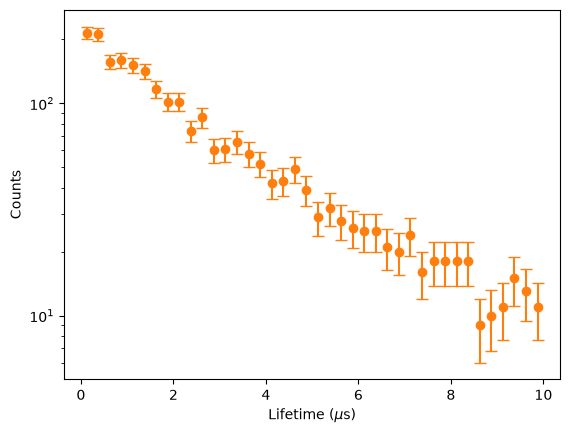

In [2]:
import numpy as np
from scipy.optimize import curve_fit
import scipy as sp
from matplotlib.pyplot import subplots

rng = np.random.default_rng(2664)
t = np.concatenate([rng.exponential(2.2, 2000),      # muon decays, tau = 2.2 us
                    rng.uniform(0, 10, 400)])        # flat background
t = t[t < 10]                                         # measured times (us)

counts, edges = np.histogram(t, bins=40, range=(0, 10))
centers = .5 * (edges[1:] + edges[:-1])

fig, ax = subplots()

ax.errorbar(centers, counts, fmt="o", yerr=np.sqrt(counts), capsize=4, color="tab:orange")

ax.set_yscale("log")

ax.set_xlabel(r"Lifetime ($\mu$s)")
ax.set_ylabel("Counts")

fit_function = lambda t, A, B, tau : A * np.exp(-t/tau) + B

popt, pcov = curve_fit(fit_function, centers, counts, p0=(centers[0], centers[-1], 2.), sigma=np.sqrt(counts), absolute_sigma=True)
punc = np.sqrt(np.diag(pcov))

print(f"Expected muon lifetime: 2.197 mus")
print(f"Fitted muon lifetime: {popt[-1]:.2f} +- {punc[-1]:.2f} mus")

chisq = np.sum(((counts - fit_function(centers, *popt))/np.sqrt(counts))**2)
pval = sp.stats.chi2.sf(chisq, len(counts) - 3)

print(f"Chi2: {chisq:.3f}")
print(f"p-value: {pval:.3f}")
print(f"The fit is not too good, as the chi2 and p-value are a bit high.")
